## CLIPTraVeLGAN https://ceur-ws.org/Vol-3387/paper1.pdf

This is a novel approach for semantically robust unpaired image translation. CLIPTraVeLGAN replaces the Siamese network in TraVeLGAN with a contrastively pretrained language-image model (CLIP) with frozen weights. This approach significantly simplifies the model selection and training process of TraVeLGAN, making it more robust and easier to use. 



## TraVeLGAN

The authors [1] introduce the concept of a transformation vector between two points. In natural language processing tasks, words are represented by points in a space in which if a certain vector would transform the word "man" into the word "woman", then the word "king" into the word "queen" would be transformed by a very similar vector. A Siamese network S represents an image by points in a certain space. In the image translation task, instead of changing the gender of the word, the transformation vector can change the background colour, size or shape of the image. But the main idea is that the vector of transformation of a point obtained from the Siamese network from one image S(xi) ("man") to a point of another original image S(xj) ("woman") will also transform the point of the generated image S (GXY (xi)) "king" to the point of the generated S(GXY(xj)) "queen".
TraVeLGAN used an additional Siamese network to encode high-level semantics between the source and target domains. This idea seemed like a breakthrough as the Siamese network was believed to outperform CycleGAN in terms of translation quality. However, TraVeLGAN has not received much development due to the difficulties in choosing the architecture of the Siamese network and the parameters of its training. This results in a large set of possible solutions and makes it difficult to determine the effectiveness of each of them. 

## CLIP

CLIP [2] was introduced as a language-image model for the transfer of knowledge without any further training. Encoders learn the internal representation of images in a shared space with the internal representation of natural language texts. 

After pretraining the model, it can be used for any purpose with any images without any tuning. Trained on a dataset of billions of image-caption pairs from the Web (WIT), the model can successfully classify images with text class labels for a wide range of tasks, even quite far from its training set: geolocation, car brands. CLIP trained on WIT shows better accuracy on ImageNet than ResNet50 trained on ImageNet. The worst performance of knowledge transfer without additional training is shown on very specialized data sets, such as classification of satellite images, medical images, and object counting in synthetic images.

Natural language encodes semantic content and hierarchical relations between concepts with words. Contrastive learning of a visual model using natural language texts as a learning cue led to the learning and generalization of such special knowledge about image elements as expressed in image-relevant texts in human language. The extent to which the visual model learns the hierarchy of concepts that exists in a human language requires separate research. Currently, CLIP reflects the meaning of the image in hidden representation most effectively among other well-known models.
The vector into which CLIP transforms images is the best choice for finding similar images. Other options for using CLIP in the search task are finding images that are most relevant to the content of some text and finding the text that most relevantly describes the image. 
Overall, CLIP's powerful internal representation of images and text make it a valuable tool for a wide range of applications, with potential future uses that have yet to be imagined.



## Semantic robustness
In [4], the concept of semantic stability of unpaired translation of images was introduced and the reasons for the conflict between compliance with the subject area and accuracy of the translation, and the reasons for hallucinating objects that are absent in the input image were highlighted. SRUNIT model is proposed to provide translation semantically robust, which is simultaneously trained with a generator and a discriminator similar to TraVeLGAN's Siamese network. CLIP is not used. In [5], the use of Vector Symbolic Architectures was proposed to improve the semantic robustness of unpaired image translation, which showed even better indicators of semantic translation accuracy than SRUNIT. CLIP is not used also.


## Our method

The core of the CLIPTraVeLGAN approach is the use of a pre-trained language-image model (CLIP) as a Siamese network in TraVeLGAN setup. The proposed CLIPTraVeLGAN model is composed of a generator, a discriminator and pretrained CLIP model. The generator takes an image from one domain and generates an image that belongs to the other domain. The discriminator is responsible for distinguishing between real and fake images. In CLIPTraVeLGAN, we replace the Siamese network in TraVeLGAN with the pre-trained language-image model CLIP. The CLIP model is used to encode the high-level semantics of the input and target domains. 

We train the CLIPTraVeLGAN model using the adversarial loss and the TraVeL loss. The adversarial loss is used to ensure that the generated image belongs to the target domain, while the TraVeL loss encourages the generator to preserve the high-level semantics of the input image. Thus, the final objective terms of the generator are: 

Lg=Ladv+λLtravel,	(1)

where λ controls the relative importance of TraVeL loss.

TraVeL loss is the same as in TraVeLGAN:   

Ltravel=ΣΣi≠j Dist[ S(Xi)-S(Xj),S(G(Xi))- S(G(Xj))] ,(2)

where Dist is a distance metric, such as cosine similarity.

One advantage of our approach is that it eliminates the need for choosing and training a Siamese network, which can be complex and time-consuming. Instead, the transfer of knowledge from CLIP to CLIPTraVeLGAN enables the generator to understand the relationships between images without any additional training. This makes our approach simpler and more straightforward, while still ensuring the high-level semantics are captured in the generated image.

In this context, the use of CLIP in CLIPTraVeLGAN adds the ability to preserve high-level semantics between the source and target domains, making the translations semantically robust. Therefore, our work builds upon the idea of TraVeLGAN and leverages the advantages of CLIP to improve the quality of unpaired image translation while maintaining semantic robustness.


## Experiment 

In this notebook we evaluate CLIPTraVeLGAN on GTA (Grand Theft Auto) [6] to Cityscapes dataset [7] which is a benchmark dataset for unpaired image translation because it involves translating images from one domain to another, where the source and target domains are vastly different. 
The GTA and Cityscapes datasets represent two different domains of real-world urban environments. The GTA dataset consists of images of urban scenes generated from a video game, while the Cityscapes dataset comprises real-world urban scenes captured by a camera mounted on a car. The images in these datasets differ in terms of lighting conditions, weather, time of day, and many other factors. The main problem is that GTA images have more sky than Cityscapes. The discriminator can easily distinct fake image by that criterion. Cityscapes images have more vegetation instead. Thus, models may hallucinate vegetation in open sky regions that is semantic mistake.


## References
[1]	Amodio, M., Krishnaswamy, S.: Travelgan: Image-to-image translation by transformation vector learning. In: Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition. pp. 8983–8992 (2019). https://arxiv.org/abs/1902.09631

[2]	Radford, A., Kim, J.W., Hallacy, C., Ramesh, A., Goh, G., Agarwal, S., Sastry, G., Askell, A., Mishkin, P., Clark, J., Krueger, G., &amp; Sutskever, I. (2021). Learning Transferable Visual Models From Natural Language Supervision. International Conference on Machine Learning. https://arxiv.org/abs/2103.00020

[3]	Zhu, J., Park, T., Isola, P., & Efros, A.A. (2017). Unpaired Image-to-Image Translation Using Cycle-Consistent Adversarial Networks. 2017 IEEE International Conference on Computer Vision (ICCV), 2242-2251. 

[4]	Zhiwei Jia et al. “Semantically Robust Unpaired Image Translation for Data with Unmatched Semantics Statistics”. In: Proceedings of the IEEE/CVF International Conference on Computer Vision. 2021, pp. 14273–14283. https://arxiv.org/abs/2012.04932

[5]	Theiss, Justin D. et al. “Unpaired Image Translation via Vector Symbolic Architectures.” European Conference on Computer Vision (2022). https://arxiv.org/abs/2209.02686

[6]	Stephan R Richter et al. “Playing for data: Ground truth from computer games”. In: European conference on computer vision. Springer. 2016, pp. 102–118.

[7]	M. Cordts, M. Omran, S. Ramos, T. Rehfeld, M. Enzweiler, R. Benenson, U. Franke, S. Roth, and B. Schiele, “The Cityscapes Dataset for Semantic Urban Scene Understanding,” in Proc. of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR), 2016. 


## Import

In [1]:
!pip install transformers -U

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 48.2 MB/s eta 0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 4.35.0
    Uninstalling transformers-4.35.0:
      Successfully uninstalled transformers-4.35.0

[notice] A new release of pip is available: 23.0.1 -> 23.3.1
[notice] To update, run: pip install --upgrade pip


In [2]:
BATCH_SIZE = 128 # change in siamis loss too

import tensorflow as tf
import tensorflow_hub as hub
import random, json, PIL, shutil, re, gc
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow_addons as tfa
from scipy import linalg
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
try:
    tpu = tf.distribute.cluster_resolver.TPUClusterResolver()
    tf.config.experimental_connect_to_cluster(tpu)
    tf.tpu.experimental.initialize_tpu_system(tpu)
    strategy = tf.distribute.experimental.TPUStrategy(tpu)
    print("on TPU")
except tf.errors.NotFoundError:
    print("not on TPU")
    strategy = tf.distribute.MirroredStrategy()
print('Number of replicas:', strategy.num_replicas_in_sync)

AUTO = tf.data.AUTOTUNE
print(tf.__version__)

AUTOTUNE = tf.data.AUTOTUNE



/usr/local/lib/python3.10/site-packages/tensorflow_addons/utils/tfa_eol_msg.py:23: UserWarning: 

TensorFlow Addons (TFA) has ended development and introduction of new features.
TFA has entered a minimal maintenance and release mode until a planned end of life in May 2024.
Please modify downstream libraries to take dependencies from other repositories in our TensorFlow community (e.g. Keras, Keras-CV, and Keras-NLP). 

For more information see: https://github.com/tensorflow/addons/issues/2807 

  warnings.warn(


INFO:tensorflow:Deallocate tpu buffers before initializing tpu system.
INFO:tensorflow:Initializing the TPU system: local


2023-11-21 20:35:55.932804: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:35:55.932913: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:35:55.932984: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:35:55.933069: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:35:55.933164: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:35:55.933363: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:35:55.933469: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority un

INFO:tensorflow:Finished initializing TPU system.


INFO:tensorflow:Found TPU system:


INFO:tensorflow:Found TPU system:


... (23 outputs left out)

INFO:tensorflow:*** Available Device: _DeviceAttributes(/job:localhost/replica:0/task:0/device:TPU:7, TPU, 0, 0)


INFO:tensorflow:*** Available Device: _DeviceAttributes(/job:localhost/replica:0/task:0/device:TPU_SYSTEM:0, TPU_SYSTEM, 0, 0)


INFO:tensorflow:*** Available Device: _DeviceAttributes(/job:localhost/replica:0/task:0/device:TPU_SYSTEM:0, TPU_SYSTEM, 0, 0)


on TPU
Number of replicas: 8
2.14.0


## Dataset

One of the competition's problems is that 300 of the images provided for training are not the same images used to compute the competition metric. Also, if we take all 1193 Monet paintings, it turns out that they correspond even less to the set on which the competition metric is based. Here, I am loading the Monet paintings numbers that I have selected, which, in my opinion, are the most suitable for achieving a high result. This aspect is not related to the implementation of CLIPTraVeLGAN, and you can use your own set of images (or the one provided in the competition).

In [3]:
best_seq = [True] * 400 + [False] * 793 # this line will work if you'll remove the next line
best_seq = list(np.load('/kaggle/input/monettrainingset/best_seq.npy', allow_pickle=True)) # remove this line to avoid error message

In [4]:
PHOTO_PATH = '/kaggle/input/gan-getting-started'
PHOTO_FILENAMES = tf.io.gfile.glob(str(PHOTO_PATH + '/photo_tfrec/*.tfrec'))

MONET_PATH1 = '/kaggle/input/monet2photo/testA'
MONET_PATH2 = '/kaggle/input/monet2photo/trainA'
MONET_FILENAMES = tf.io.gfile.glob(str(MONET_PATH1 + '/*.*'))
MONET_FILENAMES_2 = tf.io.gfile.glob(str(MONET_PATH2 + '/*.*'))
MONET_FILENAMES = MONET_FILENAMES + MONET_FILENAMES_2
print('Number of images in monet2photo: ', len(MONET_FILENAMES))

MONET_FILENAMES = np.array(MONET_FILENAMES)
MONET_FILENAMES = list(MONET_FILENAMES[best_seq])
print('Number of choosen images: ', len(MONET_FILENAMES))


Number of images in monet2photo:  1193
Number of choosen images:  392


In [5]:
IMAGE_SIZE = [256, 256]

def decode_image(image):
    image = tf.image.decode_jpeg(image, channels=3)
    image = (tf.cast(image, tf.float32) / 127.5) - 1
    image = tf.reshape(image, [*IMAGE_SIZE, 3])
    return image

def read_tfrecord(example):
    tfrecord_format = {
        "image": tf.io.FixedLenFeature([], tf.string)
    }
    example = tf.io.parse_single_example(example, tfrecord_format)
    image = decode_image(example['image'])
    return image

def load_im(filename):
    file = tf.io.read_file(filename) 
    image = tf.image.decode_jpeg(file, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)
    image = image * 2 - 1
    return image

In [6]:
with strategy.scope():
# Differentiable Augmentation for Data-Efficient GAN Training
# Shengyu Zhao, Zhijian Liu, Ji Lin, Jun-Yan Zhu, and Song Han
# https://arxiv.org/pdf/2006.10738
# from https://github.com/mit-han-lab/data-efficient-gans/blob/master/DiffAugment_tf.py



    def DiffAugment(x, policy='', channels_first=False):
        if policy:
            if channels_first:
                x = tf.transpose(x, [0, 2, 3, 1])
            for p in policy.split(','):
                for f in AUGMENT_FNS[p]:
                    x = f(x)
            if channels_first:
                x = tf.transpose(x, [0, 3, 1, 2])
        return x


    def rand_brightness(x):
        magnitude = tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) - 0.5
        x = x + magnitude
        return x


    def rand_saturation(x):
        magnitude = tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) * 2
        x_mean = tf.reduce_sum(x, axis=3, keepdims=True) * 0.3333333333333333333
        x = (x - x_mean) * magnitude + x_mean
        return x


    def rand_contrast(x):
        magnitude = tf.random.uniform([tf.shape(x)[0], 1, 1, 1]) + 0.5
        x_mean = tf.reduce_sum(x, axis=[1, 2, 3], keepdims=True) * 5.086e-6
        x = (x - x_mean) * magnitude + x_mean
        return x

    def rand_translation(x, ratio=0.125):
        batch_size = tf.shape(x)[0]
        image_size = tf.shape(x)[1:3]
        shift = tf.cast(tf.cast(image_size, tf.float32) * ratio + 0.5, tf.int32)
        translation_x = tf.random.uniform([batch_size, 1], -shift[0], shift[0] + 1, dtype=tf.int32)
        translation_y = tf.random.uniform([batch_size, 1], -shift[1], shift[1] + 1, dtype=tf.int32)
        grid_x = tf.clip_by_value(tf.expand_dims(tf.range(image_size[0], dtype=tf.int32), 0) + translation_x + 1, 0, image_size[0] + 1)
        grid_y = tf.clip_by_value(tf.expand_dims(tf.range(image_size[1], dtype=tf.int32), 0) + translation_y + 1, 0, image_size[1] + 1)
        x = tf.gather_nd(tf.pad(x, [[0, 0], [1, 1], [0, 0], [0, 0]]), tf.expand_dims(grid_x, -1), batch_dims=1)
        x = tf.transpose(tf.gather_nd(tf.pad(tf.transpose(x, [0, 2, 1, 3]), [[0, 0], [1, 1], [0, 0], [0, 0]]), tf.expand_dims(grid_y, -1), batch_dims=1), [0, 2, 1, 3])
        return x


    def rand_cutout(x, ratio=0.5):
        batch_size = tf.shape(x)[0]
        image_size = tf.shape(x)[1:3]
        cutout_size = tf.cast(tf.cast(image_size, tf.float32) * ratio + 0.5, tf.int32)
        offset_x = tf.random.uniform([tf.shape(x)[0], 1, 1], maxval=image_size[0] + (1 - cutout_size[0] % 2), dtype=tf.int32)
        offset_y = tf.random.uniform([tf.shape(x)[0], 1, 1], maxval=image_size[1] + (1 - cutout_size[1] % 2), dtype=tf.int32)
        grid_batch, grid_x, grid_y = tf.meshgrid(tf.range(batch_size, dtype=tf.int32), tf.range(cutout_size[0], dtype=tf.int32), tf.range(cutout_size[1], dtype=tf.int32), indexing='ij')
        cutout_grid = tf.stack([grid_batch, grid_x + offset_x - cutout_size[0] // 2, grid_y + offset_y - cutout_size[1] // 2], axis=-1)
        mask_shape = tf.stack([batch_size, image_size[0], image_size[1]])
        cutout_grid = tf.maximum(cutout_grid, 0)
        cutout_grid = tf.minimum(cutout_grid, tf.reshape(mask_shape - 1, [1, 1, 1, 3]))
        mask = tf.maximum(1 - tf.scatter_nd(cutout_grid, tf.ones([batch_size, cutout_size[0], cutout_size[1]], dtype=tf.float32), mask_shape), 0)
        x = x * tf.expand_dims(mask, axis=3)
        return x


    AUGMENT_FNS = {
        'color': [rand_brightness, rand_saturation, rand_contrast],
        'translation': [rand_translation],
        'cutout': [rand_cutout],
}
    def aug_fn(image):
        return DiffAugment(image,"color,translation,cutout")

In [7]:
def data_augment_flip(image):
    image = tf.image.random_flip_left_right(image)
    return image


def augment_image(image): # input data augmentation
    x = tf.random.uniform([], 0, 1.0, dtype=tf.float32)
    y = tf.random.uniform([], 0, 1.0, dtype=tf.float32)
    
    if y > .5: # random crop image
        image = tf.image.resize(image, [286, 286])
        image = tf.image.random_crop(image, size=[256, 256, 3])
            
    if x > .6: # random flip image
        image = tf.image.random_flip_left_right(image)
    
    return image



In [8]:
def load_dataset(filenames):
    dataset = tf.data.TFRecordDataset(filenames)
    dataset = dataset.map(read_tfrecord, num_parallel_calls=AUTOTUNE)
    return dataset

photo_ds = load_dataset(PHOTO_FILENAMES)
monet_ds = tf.data.Dataset.from_tensor_slices(MONET_FILENAMES).map(load_im)
monet_ds = monet_ds.repeat()
photo_ds = photo_ds.repeat()

gan_ds = tf.data.Dataset.zip((monet_ds, photo_ds)).batch(BATCH_SIZE, drop_remainder=True).prefetch(AUTOTUNE)


fast_photo_ds = load_dataset(PHOTO_FILENAMES).batch(8*strategy.num_replicas_in_sync).prefetch(4)
fid_photo_ds = load_dataset(PHOTO_FILENAMES).take(2048).batch(8*strategy.num_replicas_in_sync, drop_remainder=True).prefetch(4)
fid_monet_ds = tf.data.Dataset.from_tensor_slices(MONET_FILENAMES).map(load_im).batch(8*strategy.num_replicas_in_sync, drop_remainder=True).prefetch(4)

## FID Estimate

In [9]:
print('1 in')
# This is not real FID from Kaggle competition. Real FID function is impemented in Tensorflow 1 and may be too slow. This is my fast but not precise version
with strategy.scope():

    inception_layer = tf.keras.applications.inception_v3.InceptionV3(input_shape=(256,256,3),pooling="avg",include_top=False)

    mix3  = inception_layer.get_layer("mixed9").output
    f0 = tf.keras.layers.GlobalMaxPooling2D()(mix3)

    inception_model = tf.keras.Model(inputs=inception_layer.input, outputs=f0)
    inception_model.trainable = False

    
    def calculate_activation_statistics_mod(images,fid_model):
            act=fid_model.predict(images)
            mu = np.mean(act, axis=0)

            sigma = np.cov(act, rowvar=False)

            return mu, sigma

myFID_mu2, myFID_sigma2 = calculate_activation_statistics_mod(fid_monet_ds,inception_model)
print('end')

1 in


2023-11-21 20:36:01.991823: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:01.991946: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.


87910968/87910968 [==============================] - 0s 0us/step


2023-11-21 20:36:16.340701: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:16.341350: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:16.341915: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:16.342415: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:16.343166: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:16.344060: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:16.344951: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority un

4/6 [===================>..........] - ETA: 0s

2023-11-21 20:36:51.662049: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:51.665223: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:51.665309: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:51.665434: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:51.665540: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:51.665670: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:36:51.665780: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority un

6/6 [==============================] - 20s 51ms/step
end


In [10]:
with strategy.scope():
    def calculate_frechet_distance(mu1,sigma1,mu2,sigma2):
        fid_epsilon = 1e-14
        mu1 = np.atleast_1d(mu1)
        mu2 = np.atleast_1d(mu2)
        sigma1 = np.atleast_2d(sigma1)
        sigma2 = np.atleast_2d(sigma2)

        assert mu1.shape == mu2.shape, 'Training and test mean vectors have different lengths'
        assert sigma1.shape == sigma2.shape, 'Training and test covariances have different dimensions'

        # product might be almost singular
        covmean, _ = linalg.sqrtm(sigma1.dot(sigma2), disp=False)
  

        if not np.isfinite(covmean).all():
            msg = f'fid calculation produces singular product; adding {fid_epsilon} to diagonal of cov estimates'
            warnings.warn(msg)
            offset = np.eye(sigma1.shape[0]) * fid_epsilon
            covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
            
        # numerical error might give slight imaginary component
        if np.iscomplexobj(covmean):
#             if not np.allclose(np.diagonal(covmean).imag, 0, atol=1e-3):
#                 m = np.max(np.abs(covmean.imag))
#                 raise ValueError(f'Imaginary component {m}')
            covmean = covmean.real

        tr_covmean = np.trace(covmean)

        return (mu1 - mu2).dot(mu1 - mu2) + np.trace(sigma1) + np.trace(sigma2) - 2 * tr_covmean


    
    
    def FID(images,gen_model,inception_model=inception_model,myFID_mu2=myFID_mu2, myFID_sigma2=myFID_sigma2):
                inp = layers.Input(shape=[256, 256, 3], name='input_image')
                x = monet_generator(inp, training = False)
                x=inception_model(x)
                fid_model = tf.keras.Model(inputs=inp, outputs=x)
                
                mu1, sigma1= calculate_activation_statistics_mod(images,fid_model)

                fid_value = calculate_frechet_distance(mu1, sigma1,myFID_mu2, myFID_sigma2)

                return fid_value

## CLIP model and preprocessing according to CLIPConfig

In [11]:
    
    def get_scale_layer():
        mean = np.array([0.48145466,0.4578275,0.40821073]) * 2 - 1 
        std = np.array([0.26862954,0.26130258,0.27577711]) * 2      
        scaling_layer = keras.layers.Lambda(lambda x: ( tf.cast(x, tf.float32) - mean) / std )

        return scaling_layer
    
    
    def get_clip_model():

        layer_scaling = get_scale_layer()
        layer_permute = tf.keras.layers.Permute((3,1,2))
        backbone = TFCLIPVisionModel.from_pretrained("openai/clip-vit-large-patch14")
        
        inp = tf.keras.layers.Input(shape = [256, 256, 3]) # [B, C, H, W]
        x = inp[:,16:240,16:240,:]
        x = layer_scaling(x)
        x = layer_permute(x)
        
        output = backbone({'pixel_values':x}).pooler_output

        return tf.keras.Model(inputs=[inp], outputs=[output])

## Generator and Discriminator

In [12]:

OUTPUT_CHANNELS = 3

def down_sample(filters, size, apply_instancenorm=True):
    initializer = tf.random_normal_initializer(0., 0.02)
    gamma_init = keras.initializers.RandomNormal(mean=0.0, stddev=0.02)

    layer = keras.Sequential()
    layer.add(layers.Conv2D(filters, size, strides=2, padding='same', kernel_initializer=initializer, use_bias=False))

    if apply_instancenorm:
        layer.add(tfa.layers.InstanceNormalization(gamma_initializer=gamma_init))

    layer.add(layers.LeakyReLU())

    return layer

In [13]:
def up_sample(filters, size, apply_dropout=False):
    initializer = tf.random_normal_initializer(0., 0.02)
    gamma_init = keras.initializers.RandomNormal(mean=0.0, stddev=0.02)

    layer = keras.Sequential()
    layer.add(layers.Conv2DTranspose(filters, size, strides=2, padding='same', kernel_initializer=initializer,use_bias=False))
    layer.add(tfa.layers.InstanceNormalization(gamma_initializer=gamma_init))

    if apply_dropout:
        layer.add(layers.Dropout(0.5))

    layer.add(layers.ReLU())

    return layer

In [14]:
def Generator():
    inputs = tf.keras.layers.Input(shape=(256, 256, 3))
    initializer = tf.random_normal_initializer(0., 0.02)    
    x = tf.keras.layers.Conv2D(64, 3, padding='same', kernel_initializer=initializer,activation='relu')(inputs)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv2D(64, 3, padding='same', kernel_initializer=initializer,activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x) # 256*256*64
    
    x1 = tf.keras.layers.MaxPooling2D(padding='same')(x) # 128*128*64
    
    x1 = tf.keras.layers.Conv2D(128, 3, padding='same', kernel_initializer=initializer,activation='relu')(x1)
    x1 = tf.keras.layers.BatchNormalization()(x1)
    x1 = tf.keras.layers.Conv2D(128, 3, padding='same', kernel_initializer=initializer,activation='relu')(x1)
    x1 = tf.keras.layers.BatchNormalization()(x1)  # 128*128*128
    
    x2 = tf.keras.layers.MaxPooling2D(padding='same')(x1) # 64*64*128
    
    x2 = tf.keras.layers.Conv2D(256, 3, padding='same', kernel_initializer=initializer,activation='relu')(x2)
    x2 = tf.keras.layers.BatchNormalization()(x2)
    x2 = tf.keras.layers.Conv2D(256, 3, padding='same', kernel_initializer=initializer,activation='relu')(x2)
    x2 = tf.keras.layers.BatchNormalization()(x2)  # 64*64*256
    
    x3 = tf.keras.layers.MaxPooling2D(padding='same')(x2) # 32*32*256
    
    x3 = tf.keras.layers.Conv2D(512, 3, padding='same', kernel_initializer=initializer,activation='relu')(x3)
    x3 = tf.keras.layers.BatchNormalization()(x3)
    x3 = tf.keras.layers.Conv2D(512, 3, padding='same', kernel_initializer=initializer,activation='relu')(x3)
    x3 = tf.keras.layers.BatchNormalization()(x3)  # 32*32*512
    
    x4 = tf.keras.layers.MaxPooling2D(padding='same')(x3) # 16*16*512
    
    x4 = tf.keras.layers.Conv2D(1024, 3, padding='same', kernel_initializer=initializer,activation='relu')(x4)
    x4 = tf.keras.layers.BatchNormalization()(x4)
    x4 = tf.keras.layers.Conv2D(1024, 3, padding='same', kernel_initializer=initializer,activation='relu')(x4)
    x4 = tf.keras.layers.BatchNormalization()(x4)  # 16*16*1024
    
    x14 = tf.keras.layers.MaxPooling2D(padding='same')(x4) # 16*16*512
    
    x14 = tf.keras.layers.Conv2D(2048, 3, padding='same', kernel_initializer=initializer,activation='relu')(x14)
    x14 = tf.keras.layers.BatchNormalization()(x14)
    x14 = tf.keras.layers.Conv2D(2048, 3, padding='same', kernel_initializer=initializer,activation='relu')(x14)
    x14 = tf.keras.layers.BatchNormalization()(x14)  # 8*8*2048
    
    x15 = tf.keras.layers.Conv2DTranspose(1024, 2, strides=2, padding='same', kernel_initializer=initializer,activation='relu')(x14)
    x15 = tf.keras.layers.BatchNormalization()(x15)  # 32*32*512
    
    x16 = tf.concat([x4, x15], axis=-1) # 32*32*1024
    
    x16 = tf.keras.layers.Conv2D(1024, 3, padding='same', kernel_initializer=initializer,activation='relu')(x16)
    x16 = tf.keras.layers.BatchNormalization()(x16)
    x16 = tf.keras.layers.Conv2D(1024, 3, padding='same', kernel_initializer=initializer,activation='relu')(x16)
    x16 = tf.keras.layers.BatchNormalization()(x16)  # 32*32*512
    
    x5 = tf.keras.layers.Conv2DTranspose(1024, 2, strides=2, padding='same', kernel_initializer=initializer,activation='relu')(x16)
    x5 = tf.keras.layers.BatchNormalization()(x5)  # 32*32*512
    
    x6 = tf.concat([x3, x5], axis=-1) # 32*32*1024
    
    x6 = tf.keras.layers.Conv2D(512, 3, padding='same', kernel_initializer=initializer,activation='relu')(x6)
    x6 = tf.keras.layers.BatchNormalization()(x6)
    x6 = tf.keras.layers.Conv2D(512, 3, padding='same', kernel_initializer=initializer,activation='relu')(x6)
    x6 = tf.keras.layers.BatchNormalization()(x6)  # 32*32*512
    
    x7 = tf.keras.layers.Conv2DTranspose(256, 2, strides=2, padding='same', kernel_initializer=initializer,activation='relu')(x6)
    x7 = tf.keras.layers.BatchNormalization()(x7)  # 64*64*256
    
    x8 = tf.concat([x2, x7], axis=-1) # 64*64*512
    
    x8 = tf.keras.layers.Conv2D(256, 3, padding='same', kernel_initializer=initializer,activation='relu')(x8)
    x8 = tf.keras.layers.BatchNormalization()(x8)
    x8 = tf.keras.layers.Conv2D(256, 3, padding='same', kernel_initializer=initializer,activation='relu')(x8)
    x8 = tf.keras.layers.BatchNormalization()(x8)  # 64*64*256
    
    x9 = tf.keras.layers.Conv2DTranspose(128, 2, strides=2, padding='same', kernel_initializer=initializer,activation='relu')(x8)
    x9 = tf.keras.layers.BatchNormalization()(x9)  # 128*128*128
    
    x10 = tf.concat([x1, x9], axis=-1) # 128*128*256
    
    x10 = tf.keras.layers.Conv2D(128, 3, padding='same', kernel_initializer=initializer,activation='relu')(x10)
    x10 = tf.keras.layers.BatchNormalization()(x10)
    x10 = tf.keras.layers.Conv2D(128, 3, padding='same', kernel_initializer=initializer,activation='relu')(x10)
    x10 = tf.keras.layers.BatchNormalization()(x10)  # 128*128*128
    
    x11 = tf.keras.layers.Conv2DTranspose(64, 2, strides=2, padding='same', kernel_initializer=initializer,activation='relu')(x10)
    x11 = tf.keras.layers.BatchNormalization()(x11)  # 256*256*64
    
    x12 = tf.concat([x, x11], axis=-1) # 256*256*128
    
    x12 = tf.keras.layers.Conv2D(64, 3, padding='same', kernel_initializer=initializer,activation='relu')(x12)
    x12 = tf.keras.layers.BatchNormalization()(x12)
    x12 = tf.keras.layers.Conv2D(64, 3, padding='same', kernel_initializer=initializer,activation='relu')(x12)
    x12 = tf.keras.layers.BatchNormalization()(x12)  # 256*256*64
    

    outputs = tf.keras.layers.Conv2D(3, 1,kernel_initializer=initializer, activation='tanh')(x12) # 256*256*3
    
    return tf.keras.Model(inputs=inputs, outputs=outputs)

In [15]:
def Discriminator():
    initializer = tf.random_normal_initializer(0., 0.02)
    gamma_init = keras.initializers.RandomNormal(mean=0.0, stddev=0.02)
    
    inp = layers.Input(shape=[256, 256, 3], name='input_image')
    x = inp
    
    down1 = down_sample(64, 4, False)(x)       # (size, 128, 128, 64)
    down2 = down_sample(128, 4)(down1)         # (size, 64, 64, 128)
    down3 = down_sample(256, 4)(down2)         # (size, 32, 32, 256)

    zero_pad1 = layers.ZeroPadding2D()(down3) # (size, 34, 34, 256)
    conv = layers.Conv2D(512, 4, strides=1, kernel_initializer=initializer, use_bias=False)(zero_pad1) # (size, 31, 31, 512)

    norm1 = tfa.layers.InstanceNormalization(gamma_initializer=gamma_init)(conv)
    leaky_relu = layers.LeakyReLU()(norm1)
    zero_pad2 = layers.ZeroPadding2D()(leaky_relu) # (size, 33, 33, 512)
    last = layers.Conv2D(1, 4, strides=1, kernel_initializer=initializer)(zero_pad2) # (size, 30, 30, 1)

    return tf.keras.Model(inputs=inp, outputs=last)



# CLIP model

In [16]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
from transformers import CLIPProcessor, TFCLIPVisionModel, CLIPFeatureExtractor


/usr/local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
with strategy.scope():
    monet_generator = Generator() # transforms photos to Monet-esque paintings
    monet_discriminator = Discriminator() # differentiates real Monet paintings and generated Monet paintings
    clip_net = get_clip_model()
    clip_net.trainable = False

Some weights of the PyTorch model were not used when initializing the TF 2.0 model TFCLIPVisionModel: ['text_model.encoder.layers.1.self_attn.k_proj.bias', 'text_model.encoder.layers.11.self_attn.q_proj.bias', 'text_model.encoder.layers.0.self_attn.k_proj.bias', 'text_model.encoder.layers.6.self_attn.out_proj.weight', 'text_model.encoder.layers.7.layer_norm1.bias', 'text_model.encoder.layers.9.mlp.fc2.bias', 'text_model.encoder.layers.7.mlp.fc1.bias', 'text_model.encoder.layers.5.layer_norm1.bias', 'text_model.encoder.layers.9.self_attn.k_proj.weight', 'text_model.encoder.layers.8.self_attn.out_proj.bias', 'text_model.encoder.layers.0.mlp.fc1.weight', 'text_model.encoder.layers.11.layer_norm2.weight', 'text_model.encoder.layers.8.self_attn.q_proj.weight', 'text_model.encoder.layers.9.self_attn.v_proj.bias', 'text_model.encoder.layers.11.self_attn.v_proj.bias', 'text_model.encoder.layers.5.self_attn.v_proj.bias', 'text_model.encoder.layers.0.layer_norm2.bias', 'text_model.encoder.layers

## CLIPTraVeLGan Class

In [18]:
class CLIPTraVeLGan(keras.Model):
    def __init__(
        self,
        monet_generator,
        monet_discriminator,
        siames_net,
        lambda_id=0.00001 # balance between adversarial loss and clip loss
    ):
        super(CLIPTraVeLGan, self).__init__()
        self.m_gen = monet_generator
        self.m_disc = monet_discriminator
        self.siames_net = siames_net
        self.lambda_id = lambda_id

        
    def compile(
        self,
        m_gen_optimizer,
        m_disc_optimizer,
        gen_loss_fn,
        disc_loss_fn,
        siames_loss_fn
    ):
        super(CLIPTraVeLGan, self).compile()
        self.m_gen_optimizer = m_gen_optimizer
        self.m_disc_optimizer = m_disc_optimizer
        self.gen_loss_fn = gen_loss_fn
        self.disc_loss_fn = disc_loss_fn
        self.siames_loss_fn = siames_loss_fn
       
    
    def train_step(self, batch_data):
        real_monet, real_photo = batch_data
        batch_size = tf.shape(real_monet)[0]
        semantic_real = self.siames_net(real_photo, training=False) # CLIP embedding of real
        with tf.GradientTape(persistent=True) as tape:

            
            fake_monet = self.m_gen(real_photo, training=True)
            semantic_fake = self.siames_net(fake_monet, training=False) # CLIP embedding of fake
            
          
            ################## My code #####################
            
            both_monet = tf.concat([real_monet, fake_monet], axis=0)            
            
            aug_monet = aug_fn(both_monet)
            
            aug_real_monet = aug_monet[:batch_size]
            aug_fake_monet = aug_monet[batch_size:]
            
            ################ End of my code #################
            
            # discriminator used to check, inputing real images
            disc_real_monet = self.m_disc(aug_real_monet, training=True) # aug_real_monet

            # discriminator used to check, inputing fake images
            disc_fake_monet = self.m_disc(aug_fake_monet, training=True) # aug_fake_monet

          

            # evaluates generator loss
            monet_gen_loss = self.gen_loss_fn(disc_fake_monet)

            # evaluates discriminator loss
            monet_disc_loss = self.disc_loss_fn(disc_real_monet, disc_fake_monet)
            

            # travel loss on CLIP embeddings

            monet_travel_loss = self.siames_loss_fn(semantic_real,semantic_fake)

            # evaluates generator loss
            total_monet_gen_loss = self.gen_loss_fn(disc_fake_monet) + monet_travel_loss*self.lambda_id
            

            
        # Calculate the gradients for generator and discriminator
        monet_discriminator_gradients = tape.gradient(monet_disc_loss,
                                                      self.m_disc.trainable_variables)

        monet_generator_gradients = tape.gradient(total_monet_gen_loss,
                                                      self.m_gen.trainable_variables)


        self.m_gen_optimizer.apply_gradients(zip(monet_generator_gradients,
                                                     self.m_gen.trainable_variables))


        self.m_disc_optimizer.apply_gradients(zip(monet_discriminator_gradients,
                                                  self.m_disc.trainable_variables))


        
        return {
            "disc_real_monet":disc_real_monet,
            "disc_fake_monet": disc_fake_monet,
            "monet_disc_loss": monet_disc_loss,
            "monet_travel_loss" : monet_travel_loss,
        }

    

## Loss functions

In [19]:
with strategy.scope():
    def discriminator_loss(real, generated):
        real_loss = tf.keras.losses.BinaryCrossentropy(from_logits=True, reduction=tf.keras.losses.Reduction.NONE)(tf.ones_like(real), real)
        generated_loss = tf.keras.losses.BinaryCrossentropy(from_logits=True, reduction=tf.keras.losses.Reduction.NONE)(tf.zeros_like(generated), generated)
        total_disc_loss = real_loss + generated_loss

        return total_disc_loss * 0.5


In [20]:
with strategy.scope():
    def generator_loss(generated):
        return tf.keras.losses.BinaryCrossentropy(from_logits=True, reduction=tf.keras.losses.Reduction.NONE)(tf.ones_like(generated), generated)


In [21]:
with strategy.scope():
    def siames_loss(s1_x, s1_g):
        orders = np.array([list(range(i, 128)) + list(range(i)) for i in range(1, 128)]) # change 128 to batch_size
        orders = tf.constant(orders)
        
        orders2 = np.array([list(range(0, 128)) for i in range(1, 128)]) # change 128 to batch_size
        orders2 = tf.constant(orders2)


        dists_within_x1 = tf.gather(s1_x, orders2) - tf.gather(s1_x, orders)
        dists_within_g1 = tf.gather(s1_g, orders2) - tf.gather(s1_g, orders)
      
        cosine_loss = tf.keras.losses.CosineSimilarity(axis = 1,reduction=tf.keras.losses.Reduction.NONE)
        losses_travel_1 = tf.reduce_sum(cosine_loss(dists_within_x1, dists_within_g1) + 1)

      
        return losses_travel_1

## Create a model

In [22]:
with strategy.scope():
        gan_model = CLIPTraVeLGan(monet_generator,  monet_discriminator, clip_net)

        monet_generator.built = True
        monet_discriminator.built = True


## Training

Learnning rate = 0.0002
Stage =  1


2023-11-21 20:38:48.016324: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] model_pruner failed: INVALID_ARGUMENT: Graph does not contain terminal node Adam/AssignAddVariableOp.
2023-11-21 20:38:51.866645: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:38:51.867462: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:38:51.875261: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:38:51.884593: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:38:51.895826: E ./tensorflow/compiler/xla/stream_executor/stream_executor_internal.h:124] SetPriority unimplemented for this stream.
2023-11-21 20:38:51.929379: E ./tensorflow/compiler/xla/stream_executor/st

1400/1400 [==============================] - 1306s 856ms/step - disc_real_monet: 0.0287 - disc_fake_monet: -0.0290 - monet_disc_loss: 0.6853 - monet_travel_loss: 20671.0427
Stage =  2
1400/1400 [==============================] - 1194s 853ms/step - disc_real_monet: 0.0277 - disc_fake_monet: -0.0302 - monet_disc_loss: 0.6855 - monet_travel_loss: 14744.0635
Stage =  3
1400/1400 [==============================] - 1198s 856ms/step - disc_real_monet: 0.0275 - disc_fake_monet: -0.0296 - monet_disc_loss: 0.6856 - monet_travel_loss: 12913.7084
Stage =  4
1400/1400 [==============================] - 1196s 854ms/step - disc_real_monet: 0.0247 - disc_fake_monet: -0.0268 - monet_disc_loss: 0.6866 - monet_travel_loss: 11287.9168
Stage =  5
1400/1400 [==============================] - 1196s 854ms/step - disc_real_monet: 0.0250 - disc_fake_monet: -0.0267 - monet_disc_loss: 0.6865 - monet_travel_loss: 10623.5121
Stage =  6
1400/1400 [==============================] - 1195s 853ms/step - disc_real_monet:

2023-11-21 22:59:37.750316: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] model_pruner failed: INVALID_ARGUMENT: Graph does not contain terminal node AssignAddVariableOp.


2/2 [==============================] - 14s 34ms/step


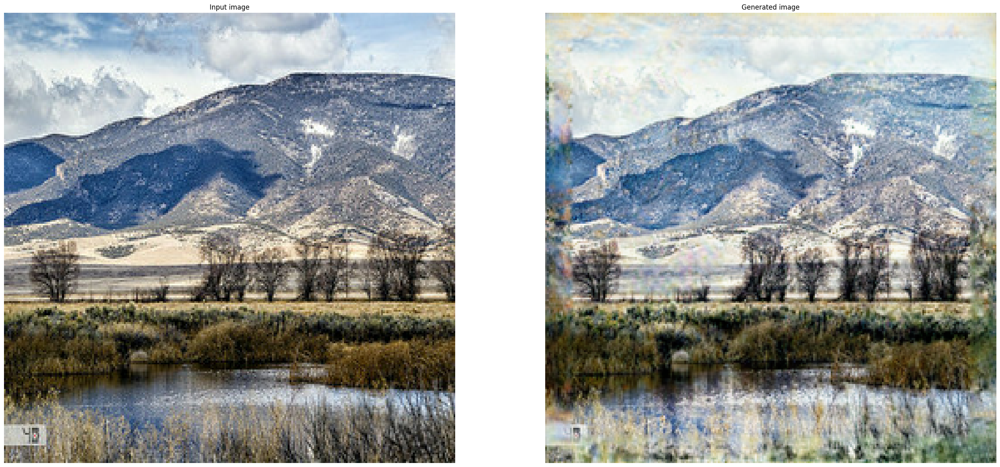

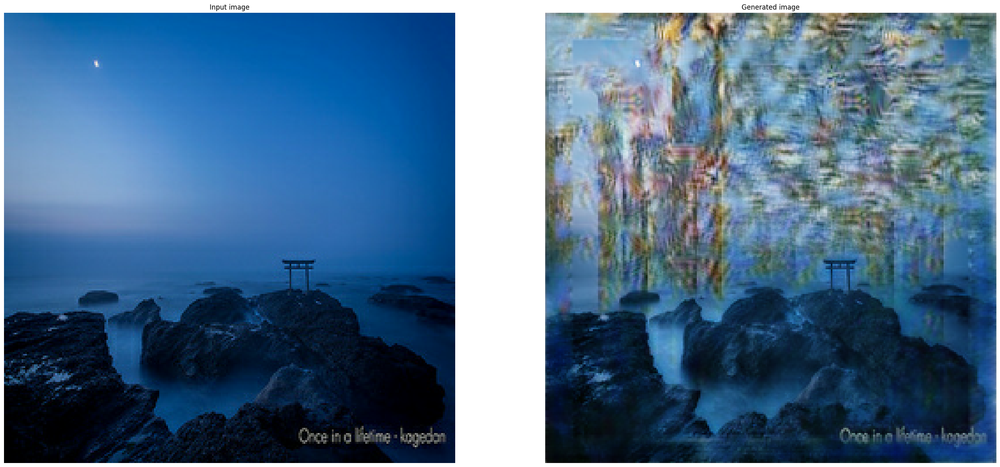

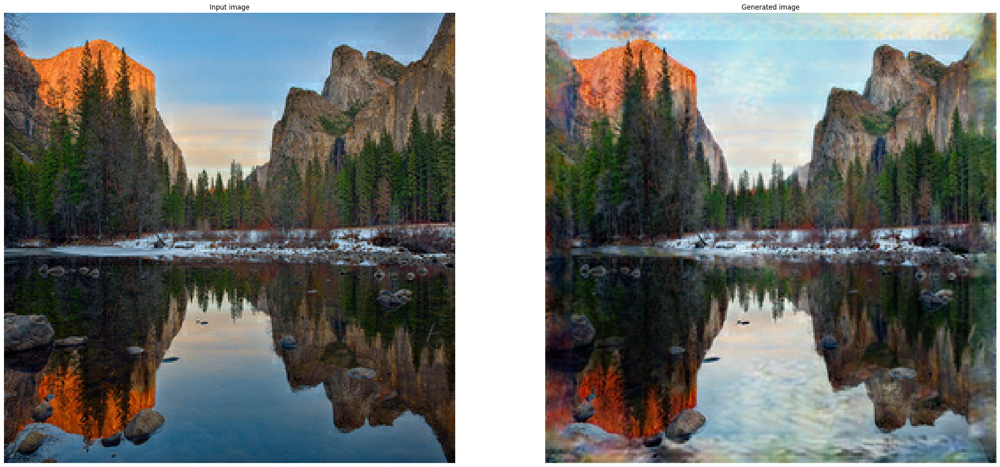

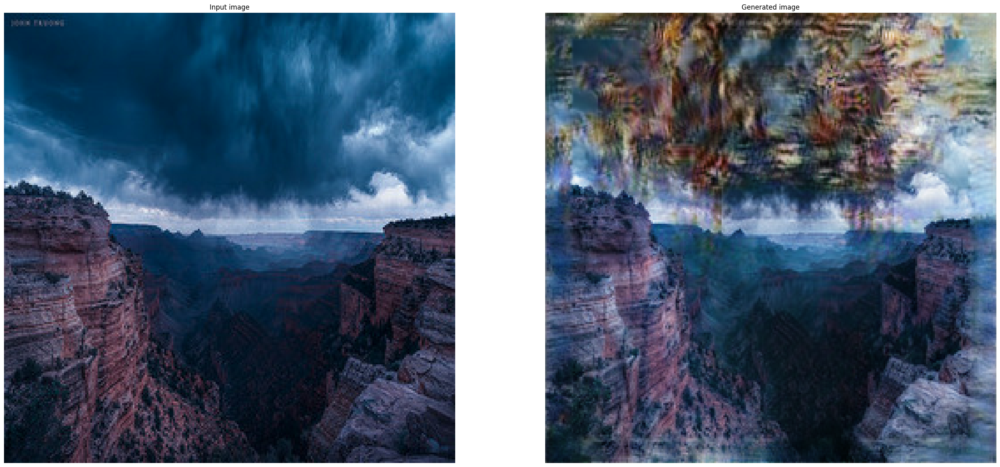

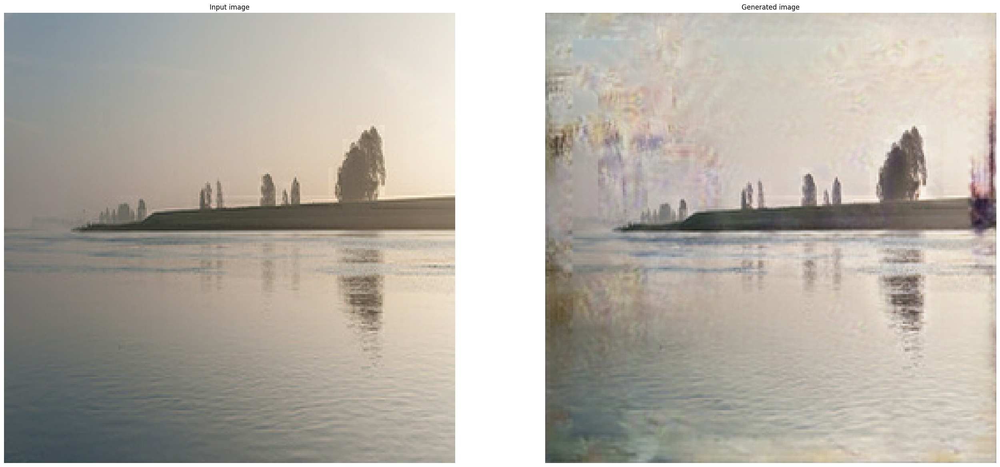

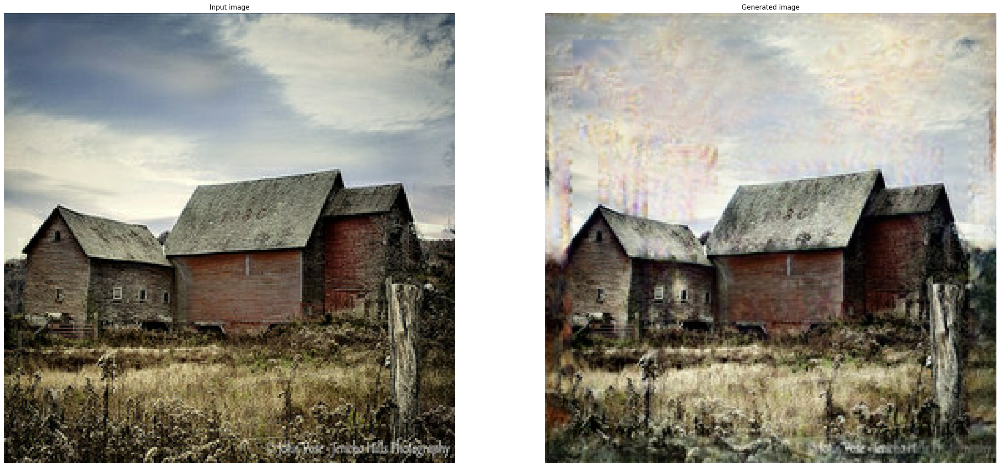

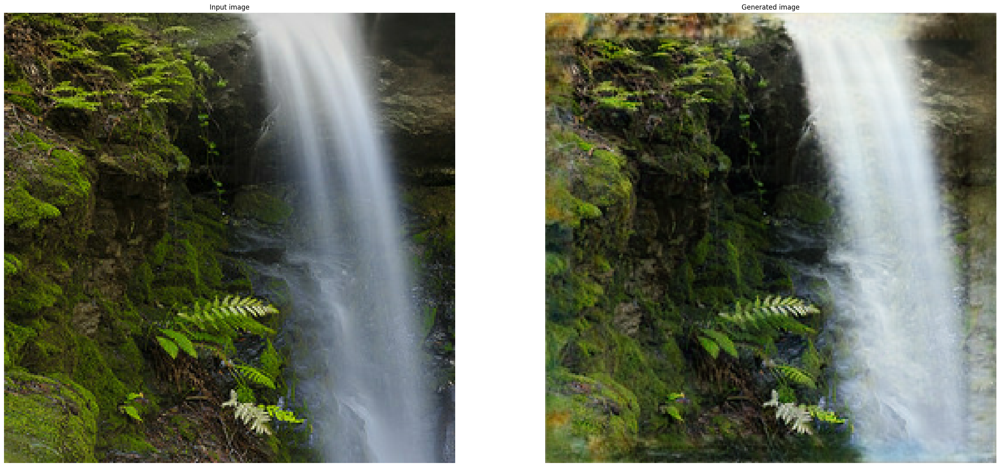

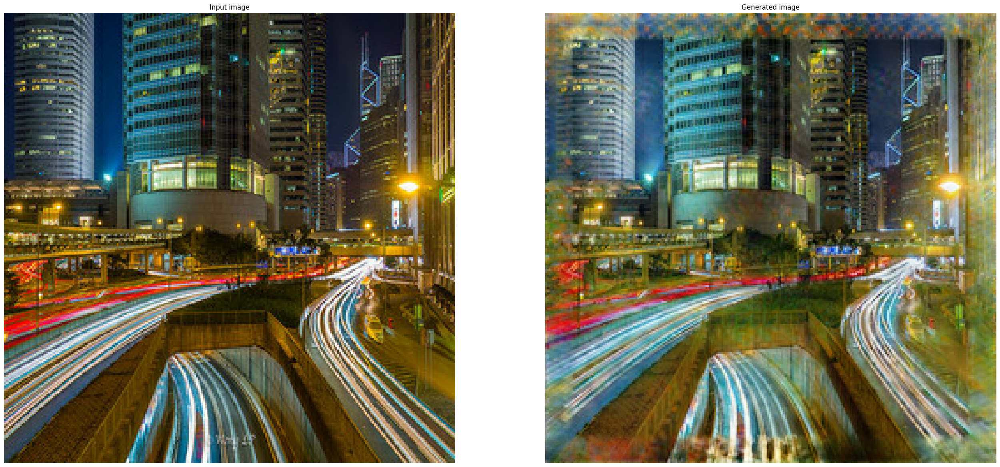

Learnning rate = 0.0001
Stage =  1
1400/1400 [==============================] - 1232s 853ms/step - disc_real_monet: 0.0408 - disc_fake_monet: -0.0417 - monet_disc_loss: 0.6801 - monet_travel_loss: 8741.5704
Stage =  2
1400/1400 [==============================] - 1192s 852ms/step - disc_real_monet: 0.0390 - disc_fake_monet: -0.0412 - monet_disc_loss: 0.6824 - monet_travel_loss: 8086.5978
Stage =  3
1400/1400 [==============================] - 1196s 854ms/step - disc_real_monet: 0.0437 - disc_fake_monet: -0.0470 - monet_disc_loss: 0.6829 - monet_travel_loss: 7725.9410
Stage =  4
1400/1400 [==============================] - 1195s 854ms/step - disc_real_monet: 0.0414 - disc_fake_monet: -0.0429 - monet_disc_loss: 0.6788 - monet_travel_loss: 6870.3596
Stage =  5
2/2 [==============================] - 0s 31ms/step


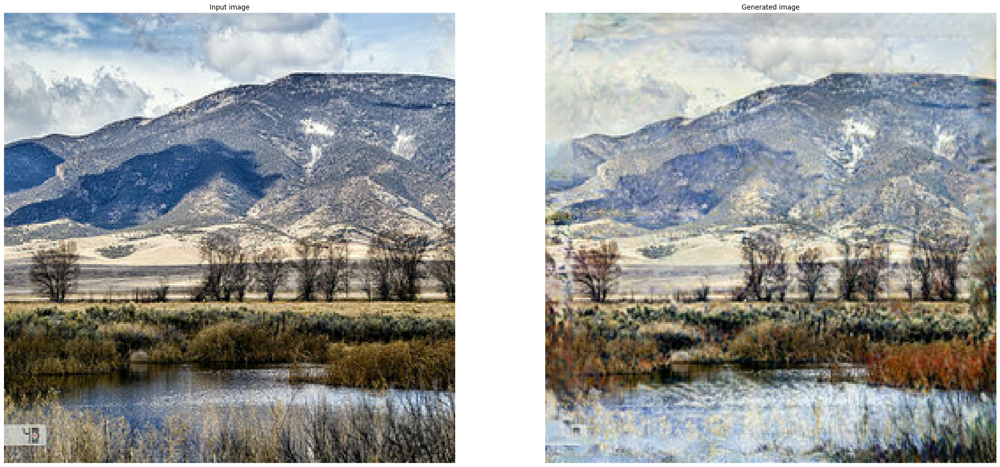

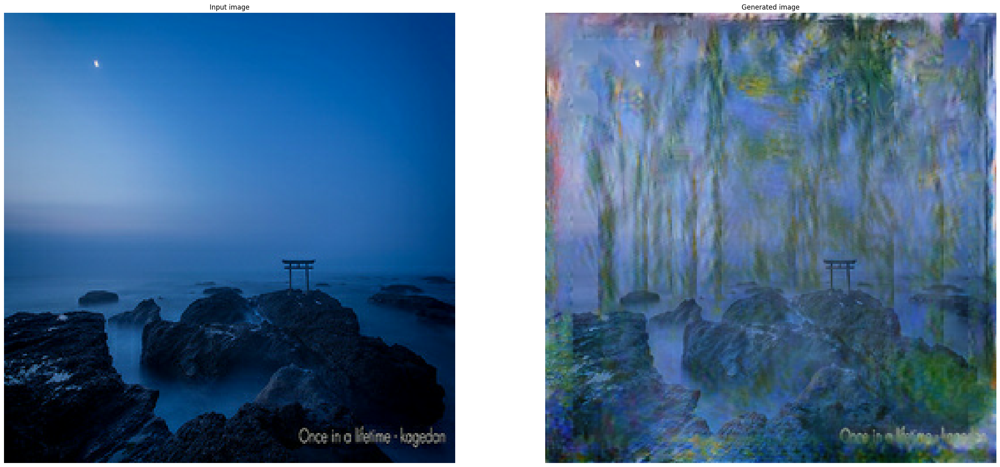

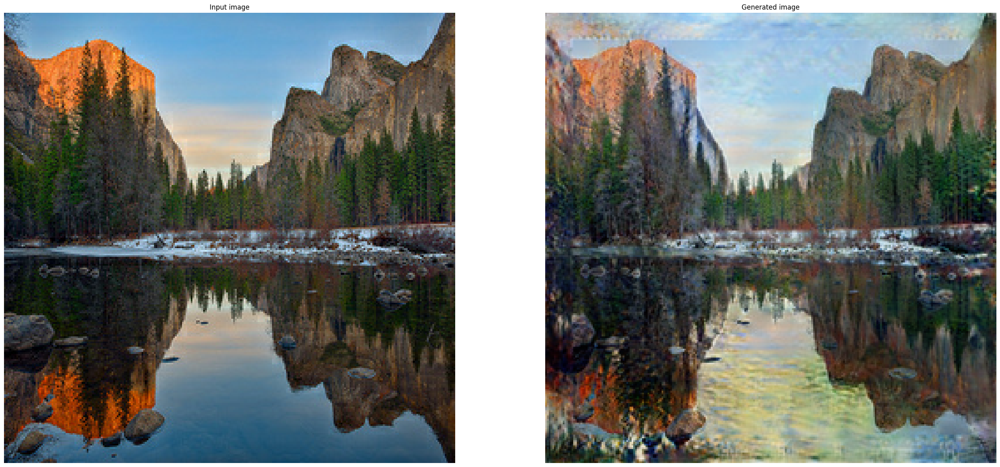

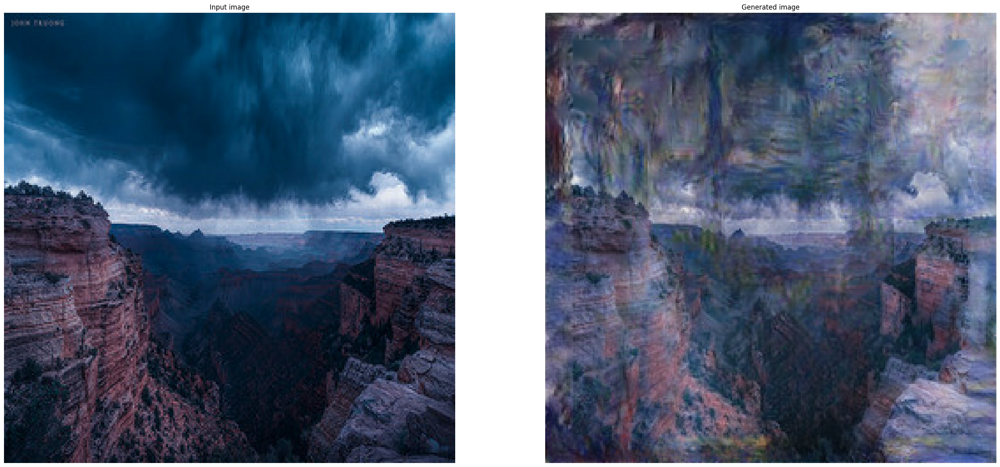

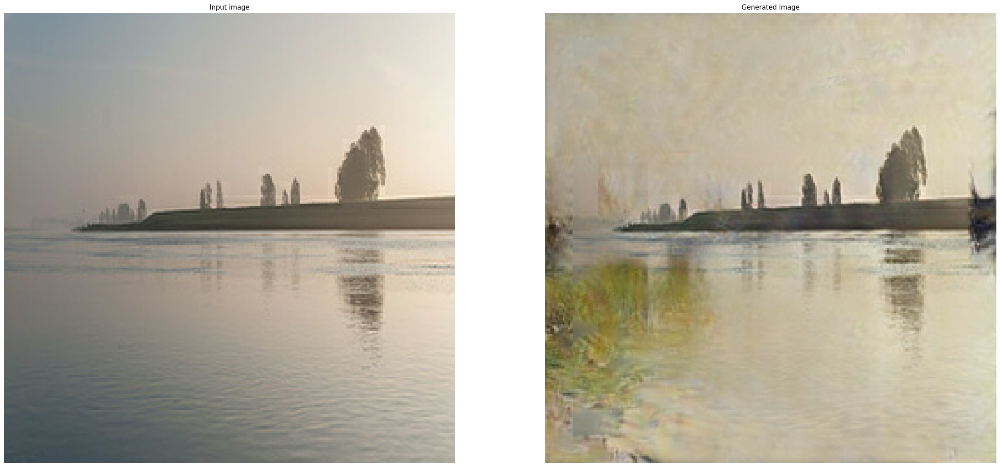

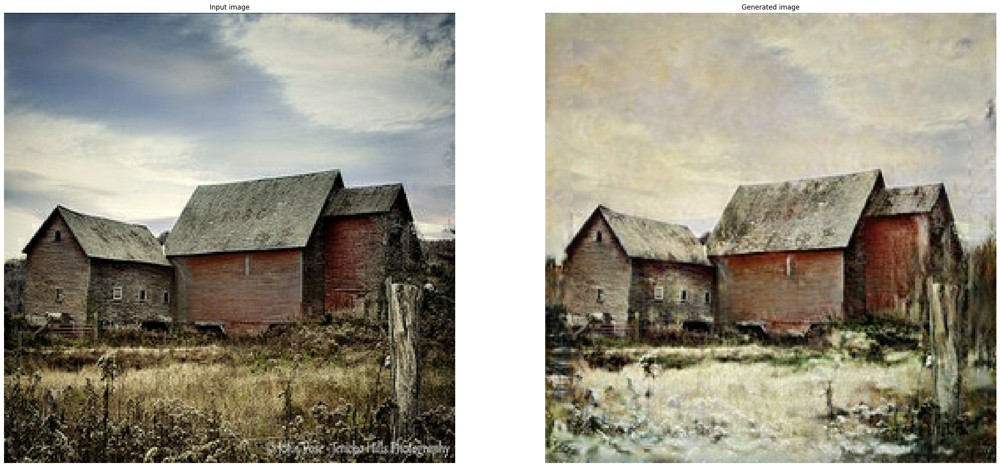

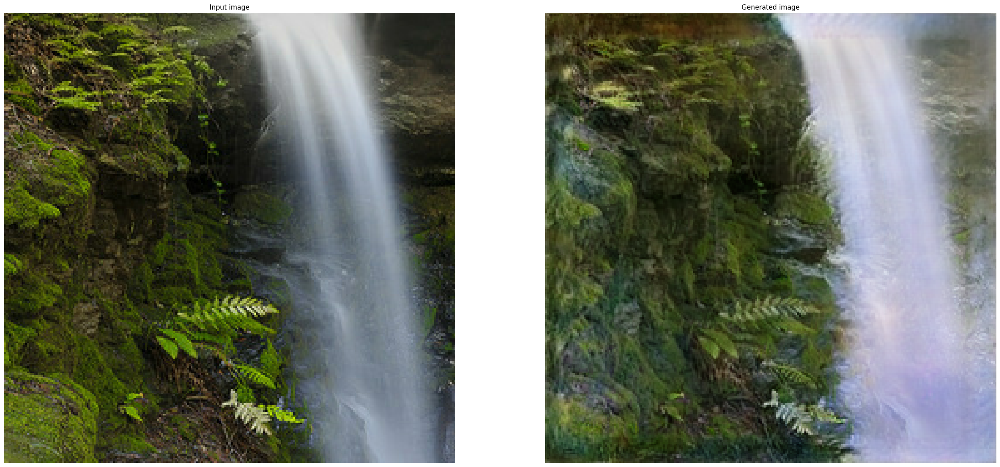

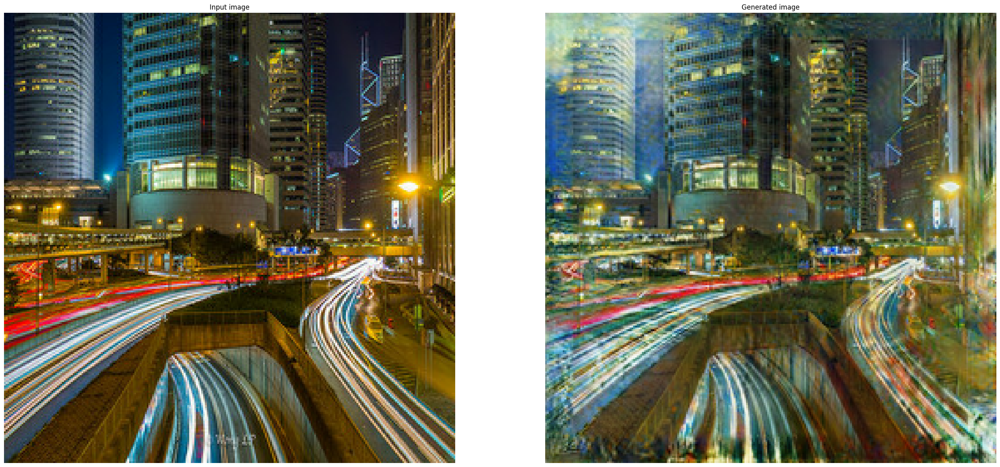

Learnning rate = 3e-05
Stage =  1


2023-11-22 00:40:45.743056: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] model_pruner failed: INVALID_ARGUMENT: Graph does not contain terminal node Adam/AssignAddVariableOp.


1400/1400 [==============================] - 1227s 849ms/step - disc_real_monet: 0.0499 - disc_fake_monet: -0.0501 - monet_disc_loss: 0.6760 - monet_travel_loss: 5096.5645
Stage =  2
2/2 [==============================] - 0s 30ms/step


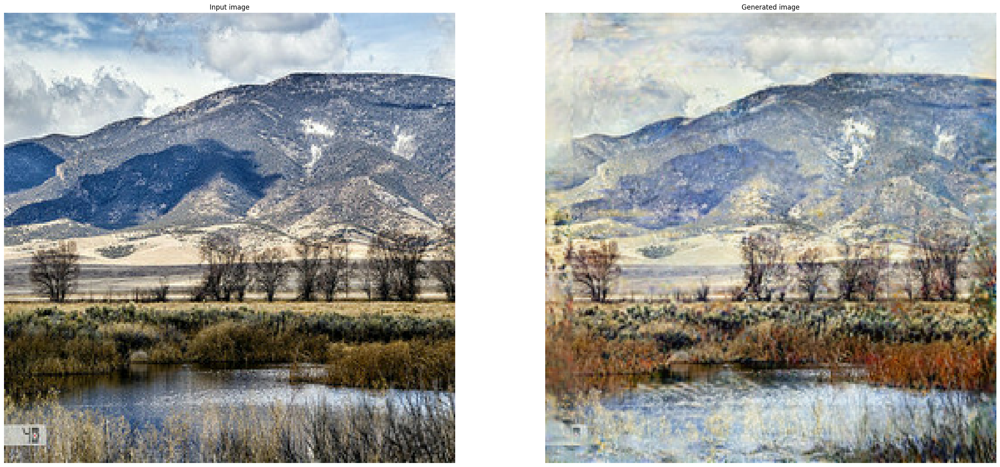

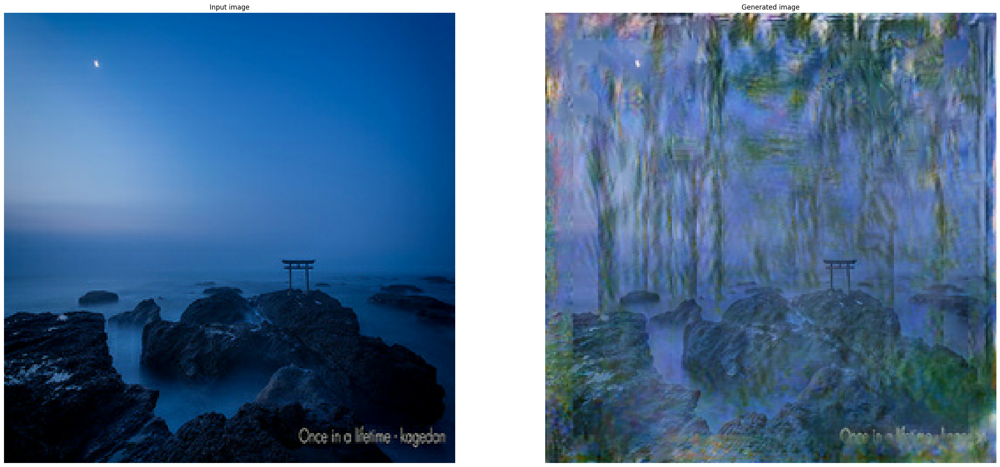

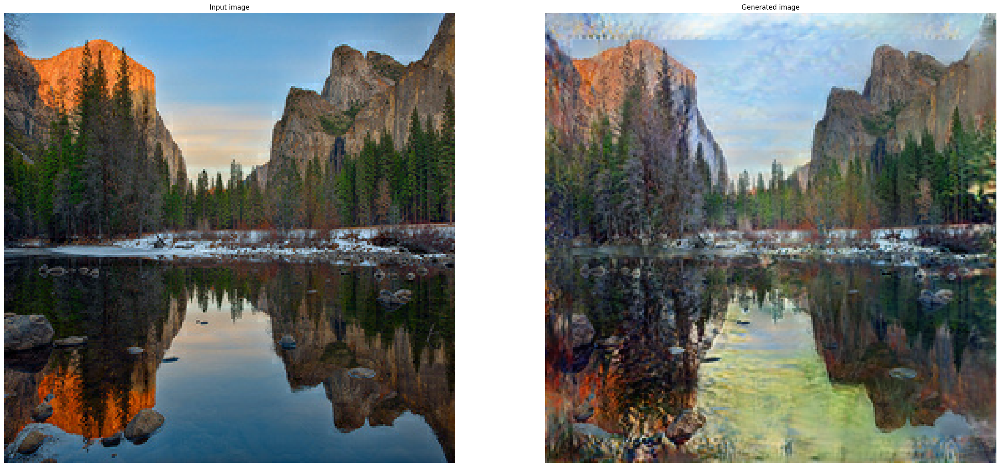

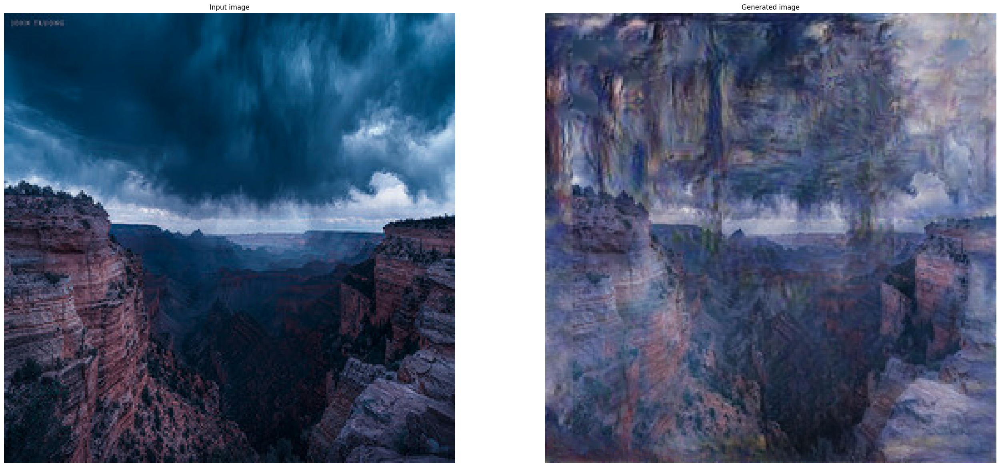

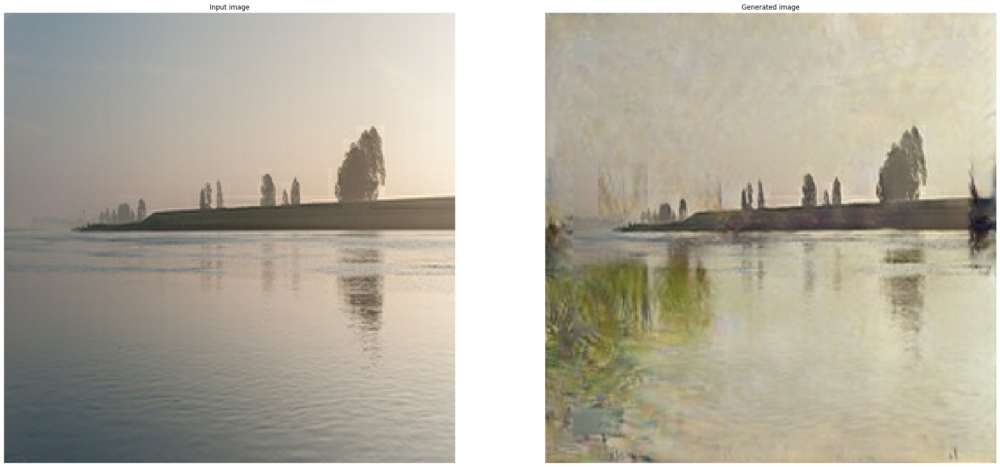

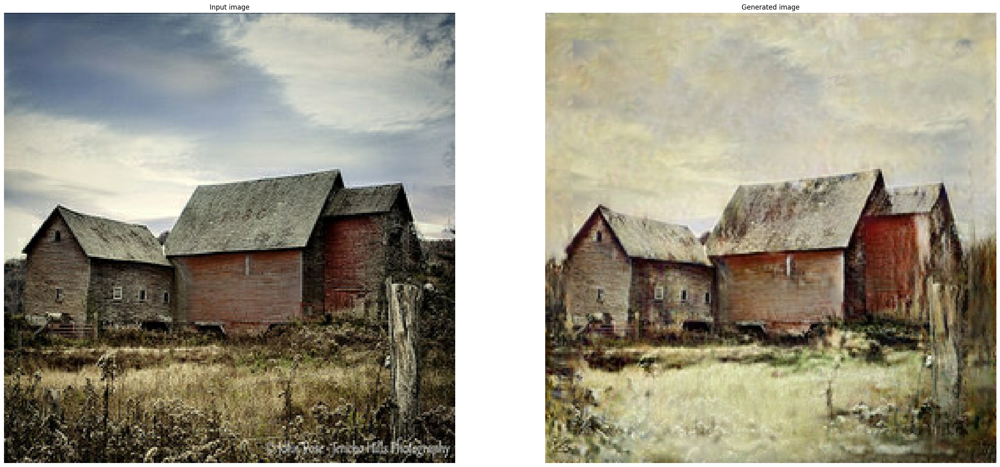

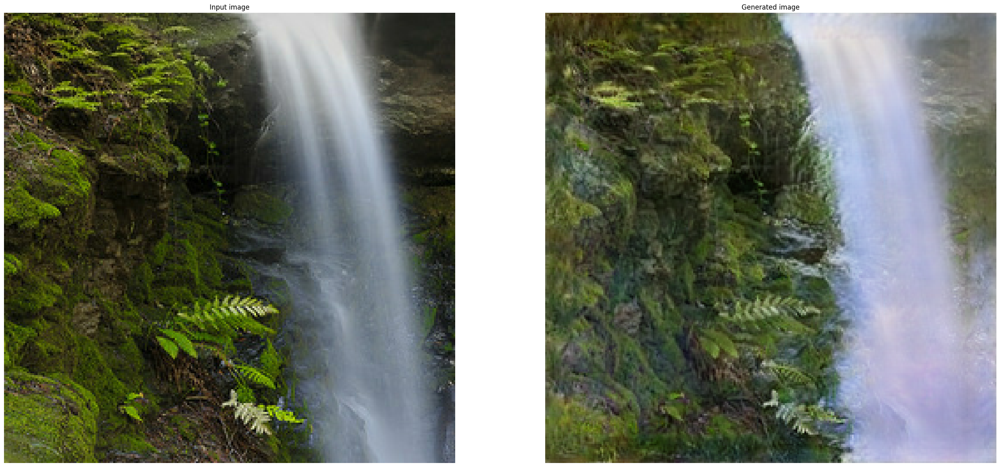

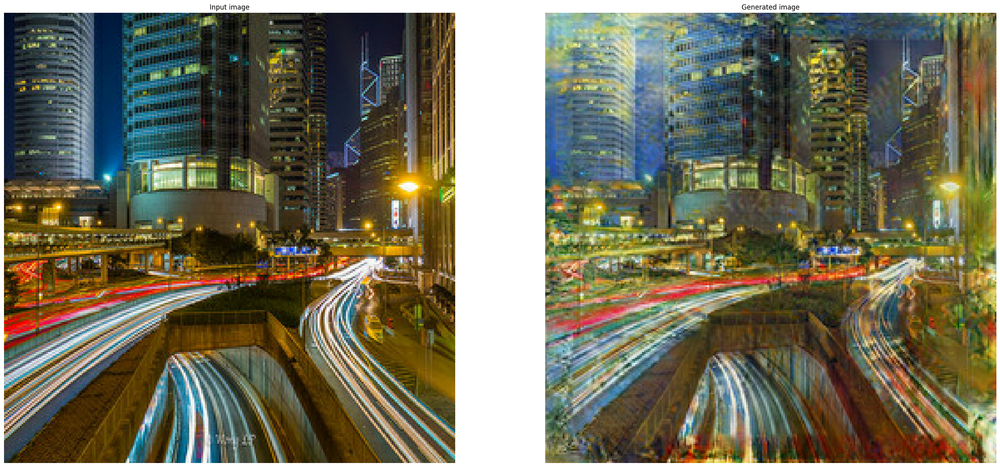

CPU times: user 5h 59min 25s, sys: 6h 16min 33s, total: 12h 15min 59s
Wall time: 4h 42min 19s


In [23]:
%%time
fids=[]
disc_m_r=[]
disc_m_f=[]
disc_m_loss=[]
best_fid=999999999

with strategy.scope():
    for (lr, stg, ep) in [(2e-4, 7, 1),(1e-4, 5, 1),(3e-5, 2, 1)]:
        print(f"Learnning rate = {lr}")
        monet_generator_optimizer = tf.keras.optimizers.Adam(lr, beta_1=0.5)
        monet_discriminator_optimizer = tf.keras.optimizers.Adam(lr * 2, beta_1=0.5) 

        gan_model.compile(
            m_gen_optimizer = monet_generator_optimizer,
            m_disc_optimizer = monet_discriminator_optimizer,
            gen_loss_fn = generator_loss,
            disc_loss_fn = discriminator_loss,
            siames_loss_fn = siames_loss,
        )

        for stage in range(1,stg+1):
            print("Stage = ", stage)
            hist = gan_model.fit(gan_ds,steps_per_epoch=1400, epochs=ep).history
            disc_m_loss.append(hist["monet_disc_loss"][0])
#             cur_fid = FID(fid_photo_ds, monet_generator)
#             fids.append(cur_fid)
#             print("After stage #{} FID = {} \n".format(stage, cur_fid))
            
#             if cur_fid<best_fid:
#                         print(f"{cur_fid} is better than previous bestFID {best_fid} \n")
#                         best_fid=cur_fid
#                         monet_generator.save_weights("monet_generator.h5")
#                         monet_discriminator.save_weights("monet_discriminator.h5")
                        
            if stage == stg:
                ds_iter = iter(fid_photo_ds)
                example_sample = next(ds_iter)
                generated_sample = monet_generator.predict(example_sample)
                for n_sample in range(8):
                      f = plt.figure(figsize=(32, 32))
                      plt.subplot(121)
                      plt.title('Input image')
                      plt.imshow(example_sample[n_sample] * 0.5 + 0.5)
                      plt.axis('off')
                      plt.subplot(122)
                      plt.title('Generated image')
                      plt.imshow(generated_sample[n_sample] * 0.5 + 0.5)
                      plt.axis('off')
                      plt.show()

#         monet_generator.load_weights("monet_generator.h5")
#         monet_discriminator.load_weights("monet_discriminator.h5")


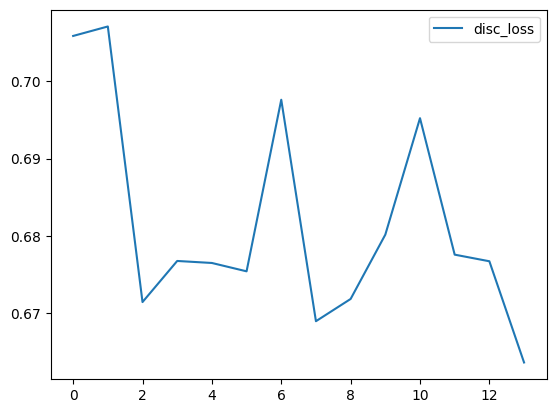

In [24]:
# print("Best FID = {} \n".format(best_fid))
disc_069=np.array(disc_m_loss).mean(axis=(1,2,3))
plt.plot(disc_069, label='disc_loss')
# plt.plot(np.array(fids)*0.001, label='FID*0.001')
plt.legend()
plt.show()

In [25]:
import PIL
! mkdir ../images

In [26]:
%%time
i = 1
for img in fast_photo_ds:
    prediction = monet_generator.predict(img)
    prediction = (prediction * 127.5 + 127.5).astype(np.uint8)
    for pred in prediction:
        im = PIL.Image.fromarray(pred)
        im.save("../images/" + str(i) + ".jpg")
        i += 1
    
    

2/2 [==============================] - 0s 30ms/step


2023-11-22 01:22:00.538901: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] model_pruner failed: INVALID_ARGUMENT: Graph does not contain terminal node AssignAddVariableOp.


2/2 [==============================] - 16s 44ms/step
CPU times: user 3min 35s, sys: 1min 28s, total: 5min 3s
Wall time: 1min 33s


In [27]:
import shutil
shutil.make_archive("/kaggle/working/images", 'zip', "/kaggle/images")

'/kaggle/working/images.zip'

## Translate training examples 

2/2 [==============================] - 0s 33ms/step


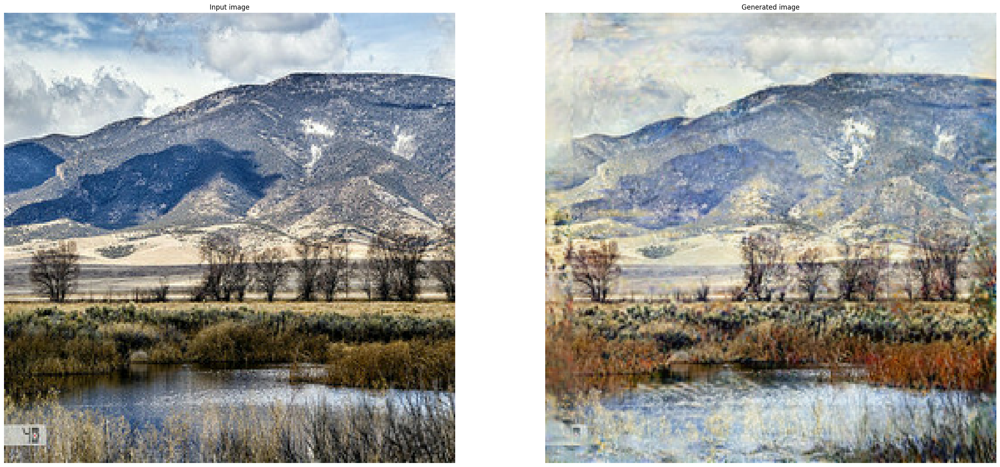

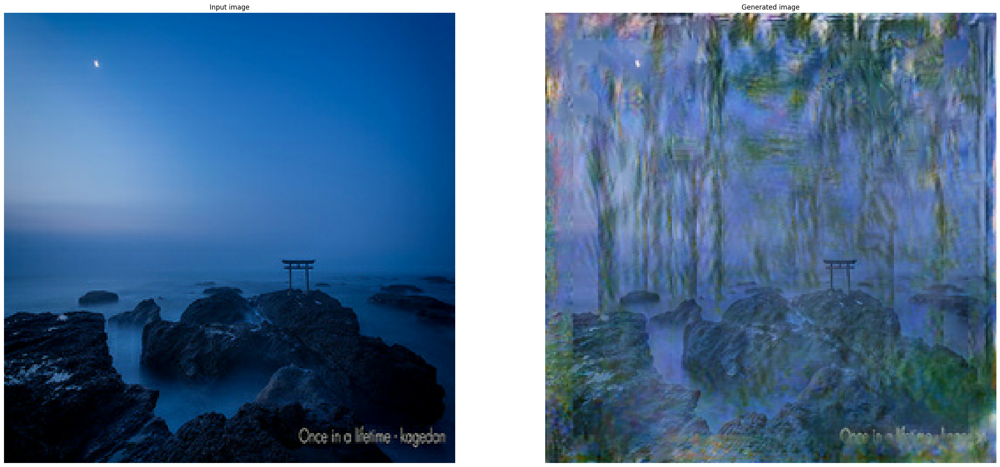

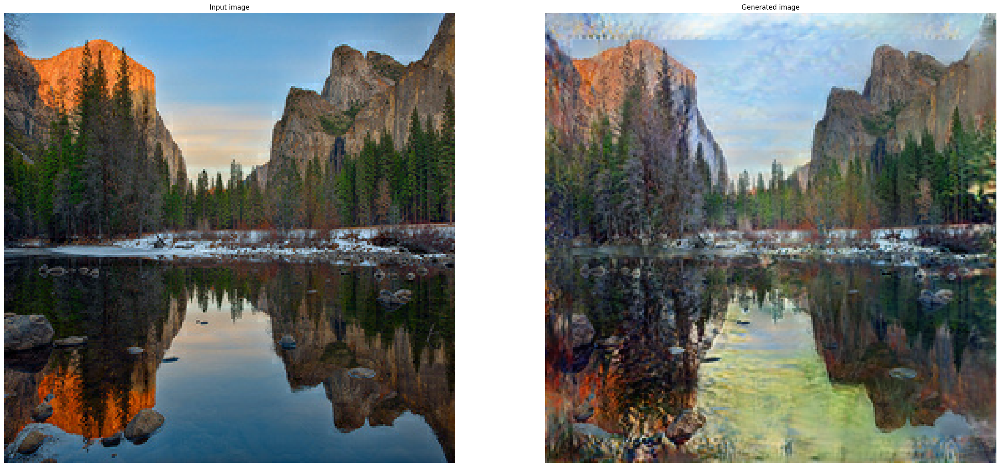

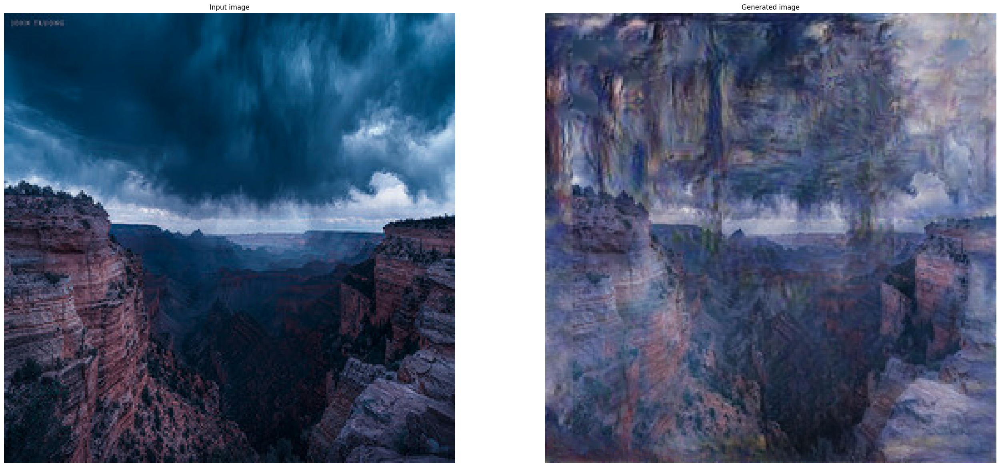

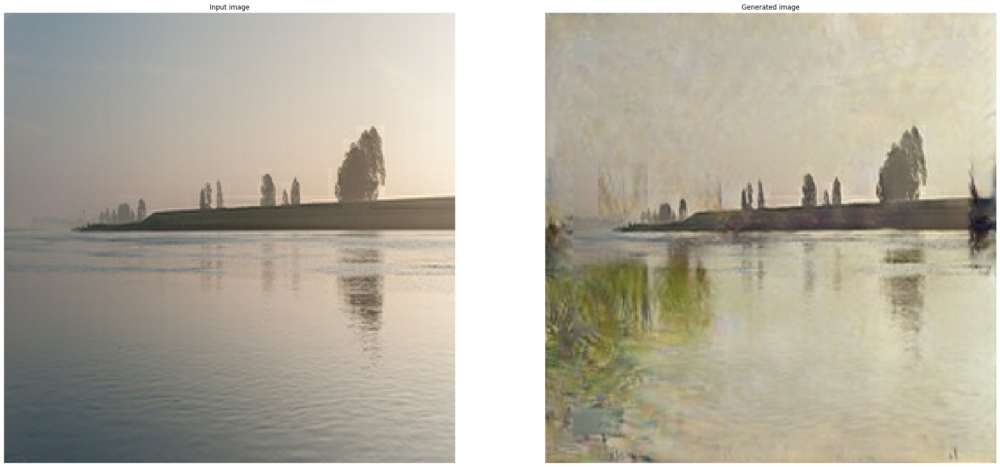

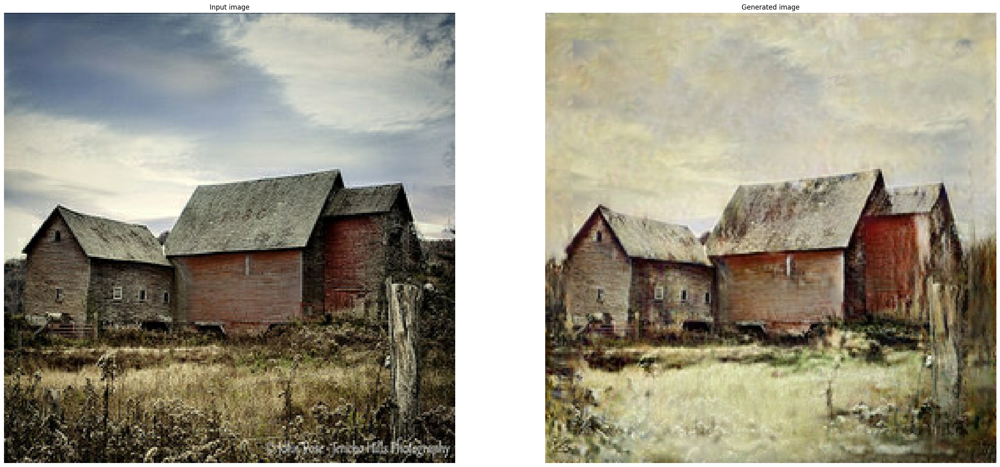

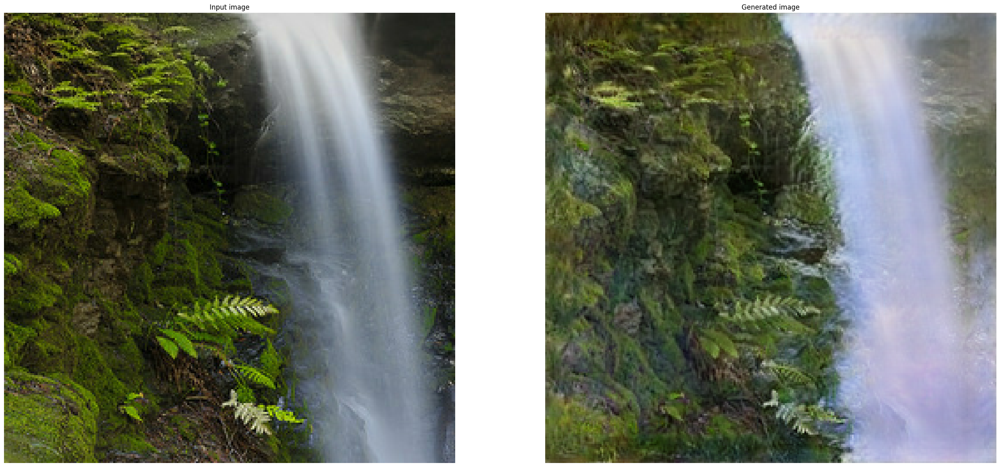

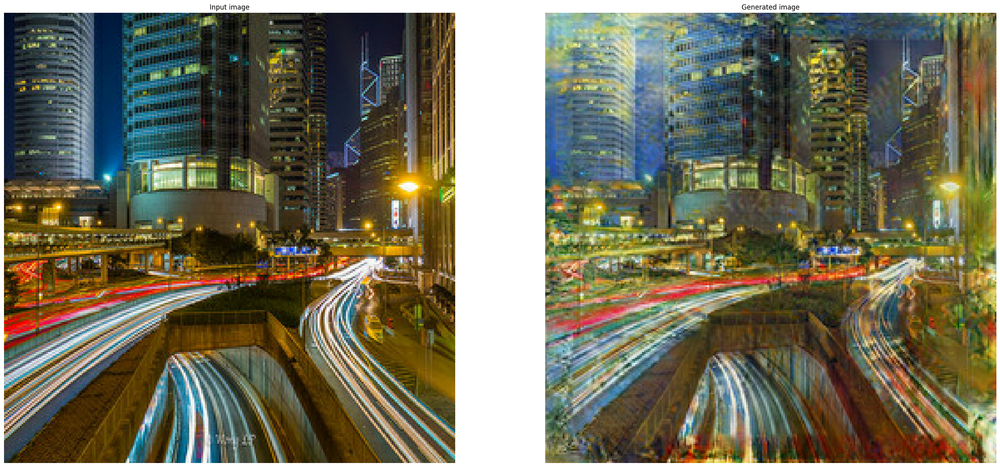

In [28]:
ds_iter = iter(fid_photo_ds)
example_sample = next(ds_iter)
# semantic_v = clip_net.predict(example_sample)
# generated_sample = monet_generator.predict([example_sample, semantic_v])
generated_sample = monet_generator.predict(example_sample)
for n_sample in range(8):

        
        f = plt.figure(figsize=(32, 32))
        
        plt.subplot(121)
        plt.title('Input image')
        plt.imshow(example_sample[n_sample] * 0.5 + 0.5)
        plt.axis('off')
        
        plt.subplot(122)
        plt.title('Generated image')
        plt.imshow(generated_sample[n_sample] * 0.5 + 0.5)
        plt.axis('off')
        plt.show()